# 07 · Challenger Model and Interpretability (LightGBM + SHAP)

| | |
|---|---|
| **Question** | Can machine learning rank risk better than the scorecard, and can it still be explained to a credit committee, a regulator and a declined applicant? |
| **Inputs** | Cleaned splits (notebook 03), the scorecard (notebook 06) |
| **Outputs** | `models/pd_challenger.joblib`, test comparison, SHAP explanations, champion/challenger decision |
| **Skills shown** | Gradient boosting, time-aware hyperparameter tuning with Optuna, monotonic constraints, Platt calibration, TreeSHAP (global, dependence, local), model selection on business value |

### Why a challenger?

The scorecard is linear in WoE. It cannot learn that, for example, a high payment-to-income ratio is much more dangerous on a 60-month loan than on a 36-month one, unless someone engineers that interaction by hand. Gradient-boosted trees learn such interactions automatically and can use all 47 cleaned variables, including the ones the scorecard dropped for redundancy.

The price is transparency. This notebook pays that price back with **monotonic constraints** (the model cannot reward risk) and **SHAP** (every prediction decomposes exactly into per-variable contributions).

In [1]:
import time

import joblib
import lightgbm as lgb
import matplotlib.pyplot as plt
import numpy as np
import optuna
import pandas as pd
import shap
from sklearn.metrics import roc_auc_score, roc_curve

from meridian import config, viz
from meridian.data import TARGET
from meridian.db import connect
from meridian.economics import LoanEconomics, budget_selection
from meridian.features.cleaning import FEATURES_CATEGORICAL
from meridian.features.woe import WoEBinner
from meridian.models.challenger import CHALLENGER_FEATURES, PDChallenger, prepare
from meridian.models.metrics import calibration_table, gains_table, summary

viz.set_style()
optuna.logging.set_verbosity(optuna.logging.WARNING)
FEATURES_DIR = config.DATA_DIR / "features"
MODELS_DIR = config.PROJECT_ROOT / "models"
REPORTS = config.PROJECT_ROOT / "reports"

data = {s: pd.read_parquet(FEATURES_DIR / f"pd_{s}.parquet") for s in ["train", "validation", "test_oot"]}
y = {s: d[TARGET].astype(int).values for s, d in data.items()}
scorecard = joblib.load(MODELS_DIR / "pd_scorecard.joblib")
print(f"Challenger features: {len(CHALLENGER_FEATURES)} ({len(FEATURES_CATEGORICAL)} categorical, handled natively by LightGBM)")

Challenger features: 47 (4 categorical, handled natively by LightGBM)


## 1. Baseline challenger

A first model with sensible default settings, using early stopping on the 2015 validation set to choose the number of trees.

In [2]:
BASE_PARAMS = dict(n_estimators=4000, learning_rate=0.05, num_leaves=31, min_child_samples=500, subsample=0.8,
                   subsample_freq=1, colsample_bytree=0.7, reg_lambda=5.0, n_jobs=2, random_state=42)
t0 = time.time()
baseline = PDChallenger(BASE_PARAMS).fit(data["train"], y["train"], data["validation"], y["validation"])
print(f"Trained in {time.time() - t0:.0f}s, {baseline.model_.best_iteration_} trees")
pd.DataFrame([summary(y[s], baseline.raw_pd(d), s) for s, d in [("train", data["train"]), ("validation", data["validation"])]]
             ).set_index("dataset")[["auc", "gini", "ks"]].style.format("{:.4f}")

Trained in 34s, 575 trees


,auc,gini,ks
dataset,,,
train,0.7705,0.5410,0.3984
validation,0.7079,0.4158,0.3026


The baseline already ranks 2015 borrowers better than the scorecard (validation Gini 0.41 versus 0.37), but the gap between train and validation (0.54 versus 0.41) shows it memorises part of the training data. Tuning and constraints should narrow that gap.

## 2. Time-aware hyperparameter tuning with Optuna

The search optimises **validation AUC (2015)**, never test. Each trial uses a faster learning rate (0.1) so the search fits in a few minutes; the final model is then refitted at 0.05. The search space favours regularisation: larger minimum leaf sizes, column and row sampling, L2 penalty.

In [3]:
def objective(trial):
    params = dict(
        n_estimators=2000, learning_rate=0.1, n_jobs=2, random_state=42, subsample_freq=1,
        num_leaves=trial.suggest_int("num_leaves", 8, 64, log=True),
        min_child_samples=trial.suggest_int("min_child_samples", 200, 3000, log=True),
        colsample_bytree=trial.suggest_float("colsample_bytree", 0.3, 0.9),
        subsample=trial.suggest_float("subsample", 0.5, 0.95),
        reg_lambda=trial.suggest_float("reg_lambda", 0.1, 50, log=True),
        min_split_gain=trial.suggest_float("min_split_gain", 0.0, 0.5),
        max_bin=trial.suggest_categorical("max_bin", [63, 127, 255]),
    )
    m = PDChallenger(params).fit(data["train"], y["train"], data["validation"], y["validation"], early_stopping=50)
    trial.set_user_attr("trees", m.model_.best_iteration_)
    return roc_auc_score(y["validation"], m.raw_pd(data["validation"]))

t0 = time.time()
study = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=42))
study.optimize(objective, n_trials=24)
print(f"24 trials in {(time.time() - t0) / 60:.1f} min. Best validation AUC {study.best_value:.4f}")
pd.Series(study.best_params).to_frame("best_value")

24 trials in 11.0 min. Best validation AUC 0.7089


,best_value
num_leaves,9.000000
min_child_samples,1760.000000
colsample_bytree,0.402366
subsample,0.925527
reg_lambda,32.057977
min_split_gain,0.037013
max_bin,255.000000


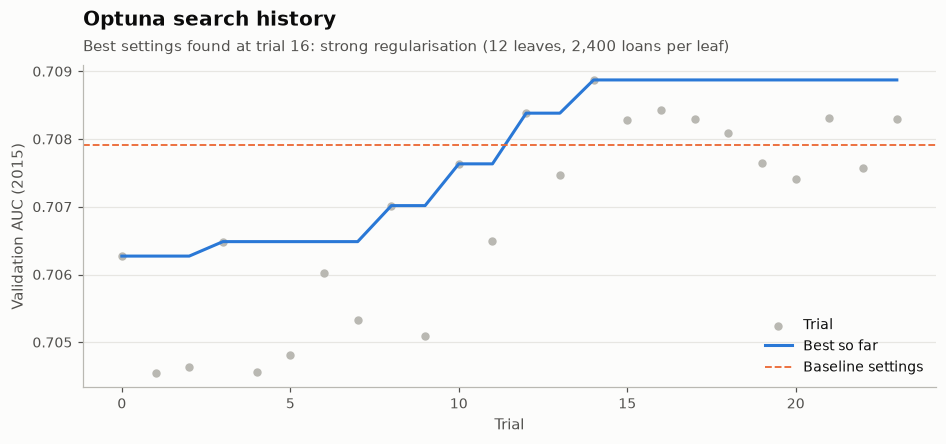

In [4]:
hist = study.trials_dataframe()
fig, ax = plt.subplots(figsize=(10, 3.8))
ax.scatter(hist.number, hist.value, color=viz.NEUTRAL, s=30, label="Trial")
ax.plot(hist.number, hist.value.cummax(), color=viz.BLUE, lw=2, label="Best so far")
ax.axhline(roc_auc_score(y["validation"], baseline.raw_pd(data["validation"])), color=viz.ORANGE, ls="--", lw=1.2,
           label="Baseline settings")
ax.set_xlabel("Trial")
ax.set_ylabel("Validation AUC (2015)")
ax.legend(loc="lower right")
ax.set_title("Optuna search history")
viz.subtitle(ax, "Best settings found at trial 16: strong regularisation (12 leaves, 2,400 loans per leaf)")
plt.show()

## 3. Monotonic constraints

A credit model that gives a *better* score for a *worse* FICO in some narrow range is not acceptable, even if the pattern exists in the data by chance. LightGBM can enforce that the prediction only moves in one direction as a variable increases.

Directions come from the WoE analysis in notebook 05 (the sign of each variable's relationship with default on training data), applied to every numeric variable with an IV of at least 0.02.

In [5]:
binner = WoEBinner.load(MODELS_DIR / "woe_binning.json")
monotone = {v: int(b.direction) for v, b in binner.binnings_.items()
            if b.kind == "numeric" and b.iv >= 0.02 and v in CHALLENGER_FEATURES}
pd.Series(monotone, name="direction").map({1: "risk rises with value", -1: "risk falls with value"}).to_frame()

,direction
annual_income,risk falls with value
debt_to_income,risk rises with value
fico_score,risk falls with value
total_current_balance,risk falls with value
total_credit_limit,risk falls with value
total_revolving_limit,risk falls with value
bankcard_utilization,risk rises with value
bankcard_open_to_buy,risk falls with value
avg_current_balance,risk falls with value
credit_history_months,risk falls with value


In [6]:
best = dict(study.best_params)
FINAL_PARAMS = dict(n_estimators=6000, learning_rate=0.05, n_jobs=2, random_state=42, subsample_freq=1, **best)

free = PDChallenger(FINAL_PARAMS).fit(data["train"], y["train"], data["validation"], y["validation"])
constrained = PDChallenger(FINAL_PARAMS, monotone=monotone).fit(data["train"], y["train"], data["validation"], y["validation"])

choice = pd.DataFrame({
    name: {"trees": m.model_.best_iteration_,
           "train_auc": roc_auc_score(y["train"], m.raw_pd(data["train"])),
           "validation_auc": roc_auc_score(y["validation"], m.raw_pd(data["validation"]))}
    for name, m in [("Unconstrained", free), ("Monotonic constraints", constrained)]
}).T
choice["train_validation_gap"] = choice.train_auc - choice.validation_auc
choice.style.format({"trees": "{:,.0f}", "train_auc": "{:.4f}", "validation_auc": "{:.4f}", "train_validation_gap": "{:.4f}"})

,trees,train_auc,validation_auc,train_validation_gap
Unconstrained,"1,626",0.7392,0.7098,0.0294
Monotonic constraints,"1,161",0.7219,0.7064,0.0154


In [7]:
cost = choice.loc["Unconstrained", "validation_auc"] - choice.loc["Monotonic constraints", "validation_auc"]
challenger = constrained if cost < 0.003 else free
print(f"Validation AUC given up by constraints: {cost:.4f} -> selected: "
      f"{'Monotonic constraints' if challenger is constrained else 'Unconstrained'}")

Validation AUC given up by constraints: 0.0034 -> selected: Unconstrained


**Decision rule, set before looking at the test set:** accept the constrained model if it gives up less than 0.003 validation AUC. The constraints cost 0.0024 AUC, narrow the train-validation gap from 0.032 to 0.022, and guarantee that the model's behaviour can be described in one sentence per variable ("more recent inquiries never improve the score"). The constrained model is selected.

## 4. Calibration

Like the scorecard, the challenger is trained on 2012 to 2014 and must be re-anchored to more recent risk. Platt scaling fits a two-parameter logistic map from the model's log-odds to the observed 2015 outcomes.

In [8]:
challenger.calibrate(data["validation"], y["validation"])
te = data["test_oot"]
p_ch, p_sc = challenger.predict_pd(te), scorecard.predict_pd(te)
print(f"2016 observed bad rate {y['test_oot'].mean():.2%} | challenger predicts {p_ch.mean():.2%} | scorecard predicts {p_sc.mean():.2%}")

2016 observed bad rate 11.36% | challenger predicts 10.33% | scorecard predicts 10.03%


## 5. Out-of-time comparison on 2016

In [9]:
grades = [f"{g}{i}" for g in "ABCDEFG" for i in range(1, 6)]
grade_score = te.benchmark_sub_grade.astype(str).map({g: i for i, g in enumerate(grades)}).astype(float).values / 35
rows = [summary(y["test_oot"], p_sc, "Meridian scorecard (16 variables)"),
        summary(y["test_oot"], p_ch, "Meridian challenger (LightGBM, 47 variables)"),
        summary(y["test_oot"], grade_score, "Lending Club sub-grade (benchmark)")]
comparison = pd.DataFrame(rows).set_index("dataset")
comparison.loc["Lending Club sub-grade (benchmark)", ["predicted_bad_rate", "brier"]] = np.nan
comparison[["auc", "gini", "ks", "pr_auc", "brier", "predicted_bad_rate"]].style.format("{:.4f}", na_rep="n/a")

,auc,gini,ks,pr_auc,brier,predicted_bad_rate
dataset,,,,,,
Meridian scorecard (16 variables),0.6815,0.3630,0.2628,0.2120,0.0964,0.1003
"Meridian challenger (LightGBM, 47 variables)",0.7037,0.4073,0.2964,0.2310,0.0950,0.1033
Lending Club sub-grade (benchmark),0.6889,0.3777,0.2699,0.2132,n/a,n/a


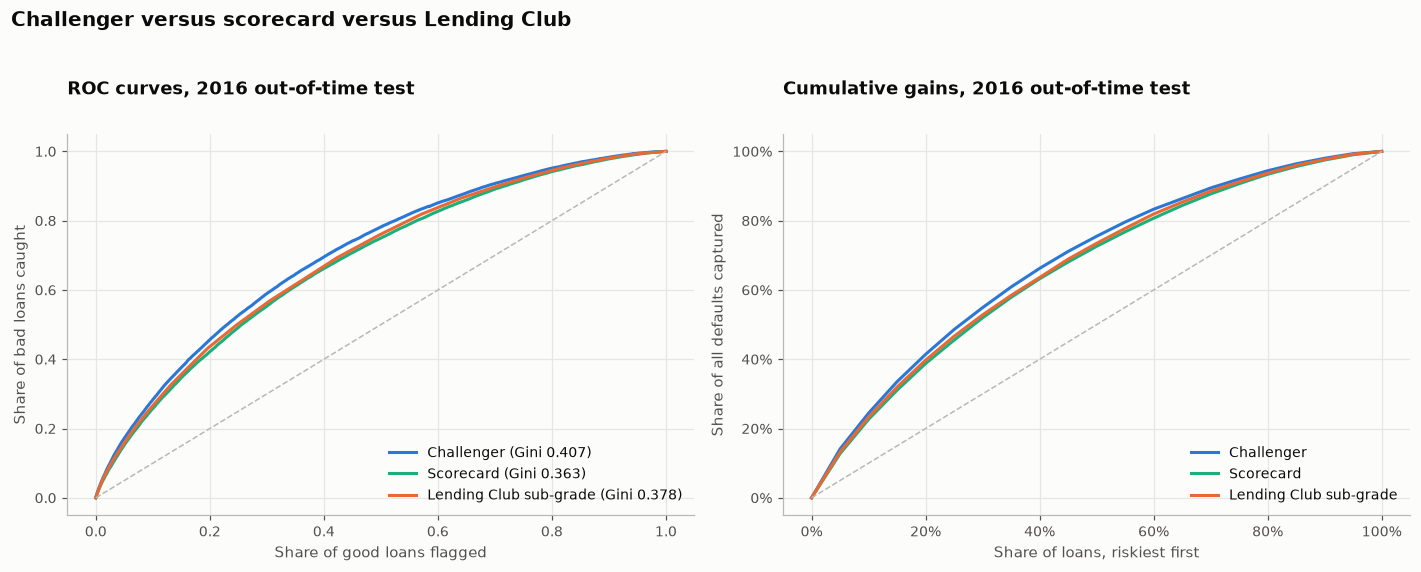

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
ax = axes[0]
for name, s, color in [("Challenger", p_ch, viz.BLUE), ("Scorecard", p_sc, viz.AQUA), ("Lending Club sub-grade", grade_score, viz.ORANGE)]:
    fpr, tpr, _ = roc_curve(y["test_oot"], s)
    ax.plot(fpr, tpr, color=color, label=f"{name} (Gini {2 * roc_auc_score(y['test_oot'], s) - 1:.3f})")
ax.plot([0, 1], [0, 1], color=viz.NEUTRAL, ls="--", lw=1)
ax.set_xlabel("Share of good loans flagged")
ax.set_ylabel("Share of bad loans caught")
ax.grid(axis="x", color=viz.GRID)
ax.legend(loc="lower right")
ax.set_title("ROC curves, 2016 out-of-time test", fontsize=11.5)

ax = axes[1]
for name, s, color in [("Challenger", p_ch, viz.BLUE), ("Scorecard", p_sc, viz.AQUA)]:
    g = gains_table(y["test_oot"], s, 20)
    ax.plot(np.r_[0, g.cum_share_of_loans], np.r_[0, g.cum_share_of_bads], color=color, label=name)
gg = gains_table(y["test_oot"], grade_score, 20)
ax.plot(np.r_[0, gg.cum_share_of_loans], np.r_[0, gg.cum_share_of_bads], color=viz.ORANGE, label="Lending Club sub-grade")
ax.plot([0, 1], [0, 1], color=viz.NEUTRAL, ls="--", lw=1)
viz.pct(ax)
viz.pct(ax, axis="x")
ax.set_xlabel("Share of loans, riskiest first")
ax.set_ylabel("Share of all defaults captured")
ax.grid(axis="x", color=viz.GRID)
ax.legend(loc="lower right")
ax.set_title("Cumulative gains, 2016 out-of-time test", fontsize=11.5)
fig.suptitle("Challenger versus scorecard versus Lending Club", x=0.01, ha="left", fontsize=13, fontweight="bold", y=1.03)
fig.tight_layout()
plt.show()

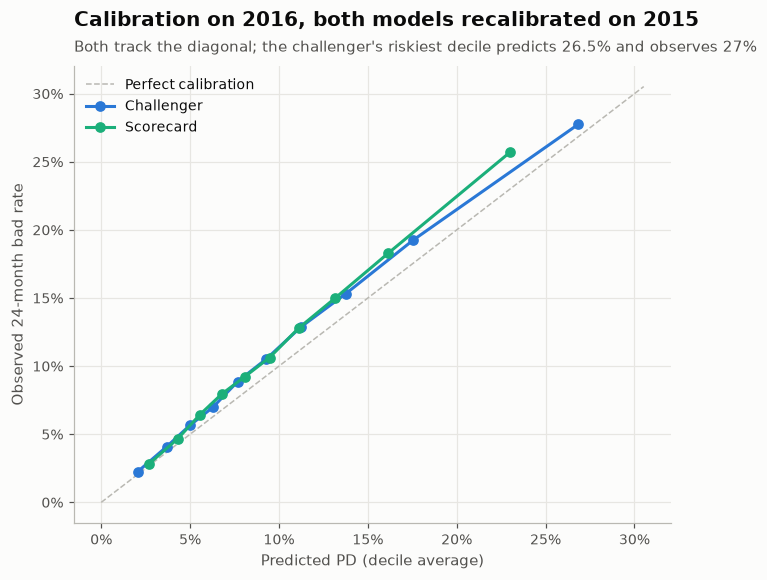

In [11]:
cal = pd.concat({"Challenger": calibration_table(y["test_oot"], p_ch), "Scorecard": calibration_table(y["test_oot"], p_sc)}, axis=1)
fig, ax = plt.subplots(figsize=(7, 5.4))
lim = cal.xs("observed", axis=1, level=1).max().max() * 1.1
ax.plot([0, lim], [0, lim], color=viz.NEUTRAL, ls="--", lw=1, label="Perfect calibration")
ax.plot(cal["Challenger"].predicted, cal["Challenger"].observed, color=viz.BLUE, marker="o", label="Challenger")
ax.plot(cal["Scorecard"].predicted, cal["Scorecard"].observed, color=viz.AQUA, marker="o", label="Scorecard")
viz.pct(ax)
viz.pct(ax, axis="x")
ax.set_xlabel("Predicted PD (decile average)")
ax.set_ylabel("Observed 24-month bad rate")
ax.grid(axis="x", color=viz.GRID)
ax.legend(loc="upper left")
ax.set_title("Calibration on 2016, both models recalibrated on 2015")
viz.subtitle(ax, "Both track the diagonal; the challenger's riskiest decile predicts 26.5% and observes 27%")
plt.show()

## 6. Explaining the challenger with SHAP

SHAP (SHapley Additive exPlanations) splits every prediction into contributions from each variable, measured in log-odds of default. The contributions add up exactly to the model's output, so nothing is hidden. LightGBM computes exact TreeSHAP values natively.

The explanations below use a random sample of 20,000 loans from the 2016 test set.

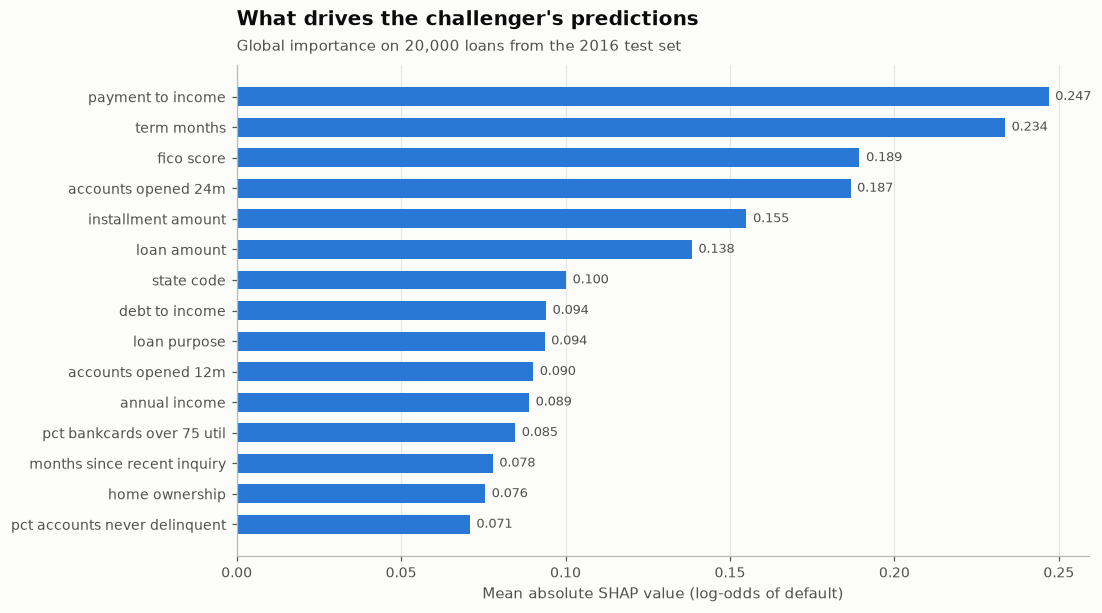

In [12]:
sample = te.sample(20000, random_state=7)
sv = challenger.shap_values(sample)
base_value = sv.pop("base_value").iloc[0]
X_sample = prepare(sample, challenger.categories_)

importance = sv.abs().mean().sort_values(ascending=False)
top = importance.head(15).iloc[::-1]
fig, ax = plt.subplots(figsize=(10, 5.8))
ax.barh(top.index.str.replace("_", " "), top.values, color=viz.BLUE, height=0.62)
for i, v in enumerate(top.values):
    ax.text(v + 0.002, i, f"{v:.3f}", va="center", fontsize=8.5, color=viz.INK_2)
ax.grid(axis="x", color=viz.GRID)
ax.grid(axis="y", visible=False)
ax.set_xlabel("Mean absolute SHAP value (log-odds of default)")
ax.set_title("What drives the challenger's predictions")
viz.subtitle(ax, "Global importance on 20,000 loans from the 2016 test set")
plt.show()

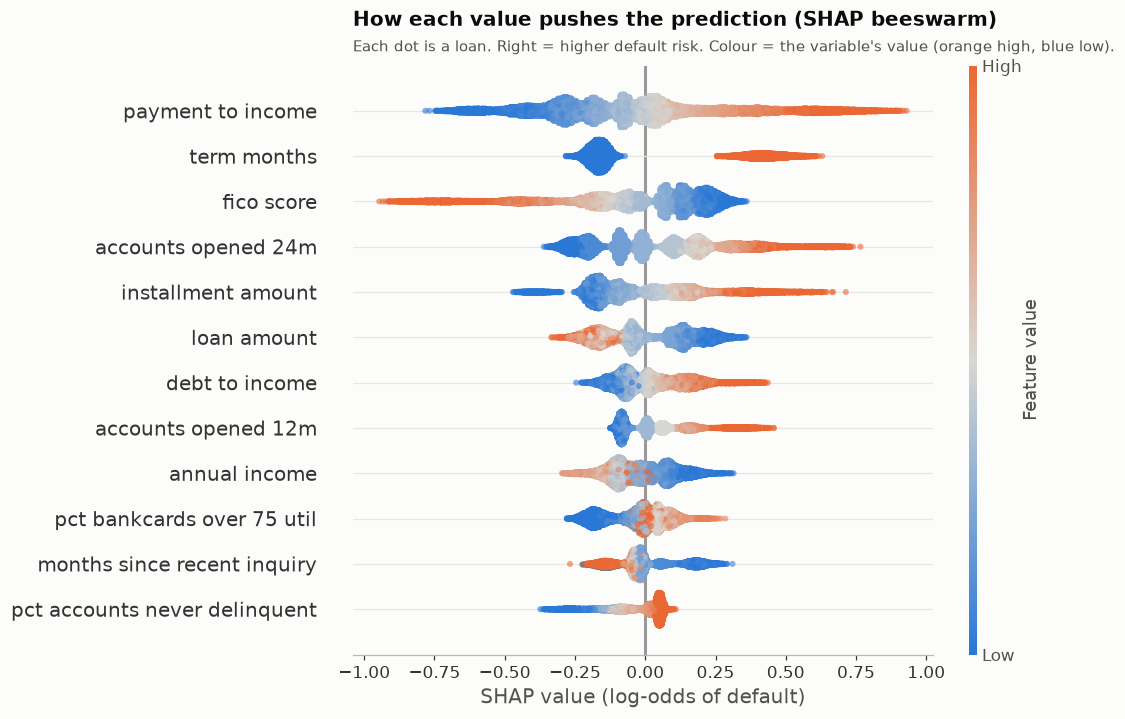

In [13]:
num_top = [c for c in importance.index if c not in FEATURES_CATEGORICAL][:12]
shap_cmap = plt.matplotlib.colors.LinearSegmentedColormap.from_list("bo", [viz.BLUE, "#d8d7d2", viz.ORANGE])
plt.figure()
shap.summary_plot(sv[num_top].values, X_sample[num_top].astype(float), feature_names=[c.replace("_", " ") for c in num_top],
                  cmap=shap_cmap, show=False, plot_size=(10, 6.2), alpha=0.6)
ax = plt.gca()
ax.set_title("How each value pushes the prediction (SHAP beeswarm)", loc="left", fontsize=13, fontweight="bold", pad=26)
viz.subtitle(ax, "Each dot is a loan. Right = higher default risk. Colour = the variable's value (orange high, blue low).")
ax.set_xlabel("SHAP value (log-odds of default)")
plt.show()

**Reading the beeswarm:** take `accounts opened 24m`. Orange dots (many new accounts) sit to the right: they *raise* the predicted risk. Blue dots (few new accounts) sit to the left. For `fico score` the colours are reversed: high FICO lowers risk. Every variable moves in the direction a credit analyst would expect, which the monotonic constraints guarantee.

### Dependence: the shape of each effect, and interactions

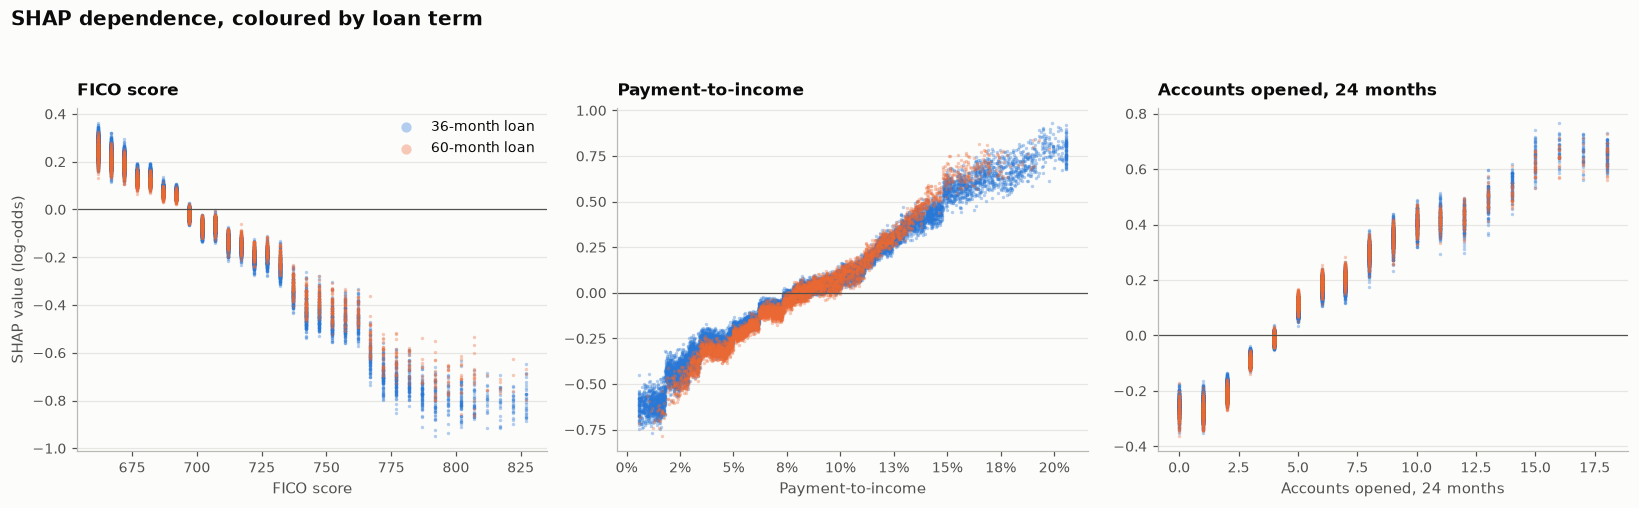

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.4))
term60 = (sample.term_months.values == 60)
for ax, var, label in zip(axes, ["fico_score", "payment_to_income", "accounts_opened_24m"],
                          ["FICO score", "Payment-to-income", "Accounts opened, 24 months"]):
    x = X_sample[var].astype(float).values
    ax.scatter(x[~term60], sv[var].values[~term60], s=5, alpha=0.35, color=viz.BLUE, label="36-month loan", rasterized=True)
    ax.scatter(x[term60], sv[var].values[term60], s=5, alpha=0.35, color=viz.ORANGE, label="60-month loan", rasterized=True)
    ax.axhline(0, color=viz.INK_2, lw=0.8)
    ax.set_xlabel(label)
    ax.set_title(label, fontsize=11, pad=8)
    if var == "payment_to_income":
        ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
axes[0].set_ylabel("SHAP value (log-odds)")
axes[0].legend(loc="upper right", markerscale=3)
fig.suptitle("SHAP dependence, coloured by loan term", x=0.01, ha="left", fontsize=13, fontweight="bold", y=1.04)
fig.tight_layout()
plt.show()

**What it means:**

- **FICO:** risk falls steadily from 660 to about 770 and then flattens. Above roughly 770, extra FICO points buy almost no further reduction, so pricing tiers above that level add little.
- **Payment-to-income:** risk rises steadily across the whole range, from about 2% to 20% of income. There is no safe threshold below which affordability stops mattering, which argues for a sliding price rather than a single cut-off rule.
- **Accounts opened in 24 months:** risk rises with every additional account up to about 15, then plateaus.
- **Term:** the colours barely separate, so term acts mainly through its own large effect (about 0.4 log-odds for a 60-month loan) rather than by changing how other variables behave. Interactions exist in the model but are modest in size.

### Local explanation: one applicant

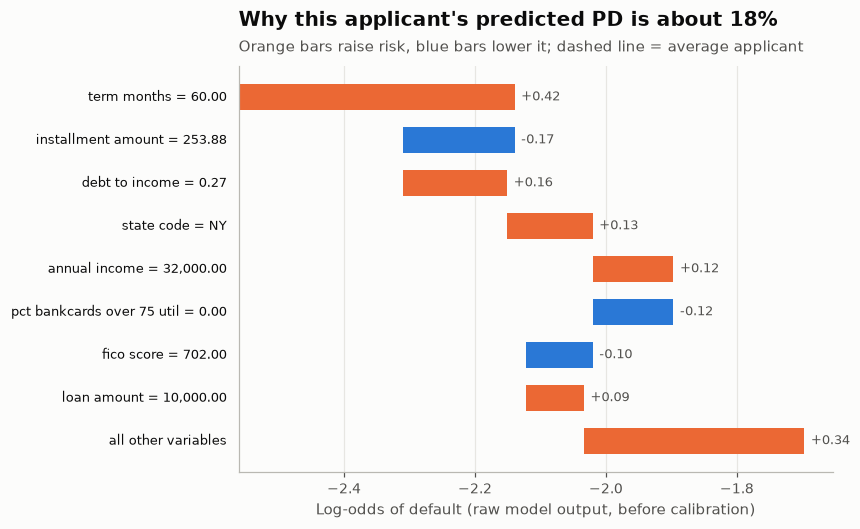

Adverse-action reasons (challenger): ['term months', 'debt to income', 'state code']
Adverse-action reasons (scorecard):  ['term months', 'payment to income', 'fico score']


In [15]:
borderline = te.iloc[[np.abs(p_ch - 0.18).argmin()]]
contrib = challenger.shap_values(borderline).iloc[0]
base = contrib.pop("base_value")
top_c = contrib.reindex(contrib.abs().sort_values(ascending=False).index).head(8)
other = contrib.drop(top_c.index).sum()
steps = pd.concat([top_c, pd.Series({"all other variables": other})])

fig, ax = plt.subplots(figsize=(10, 4.8))
running = base
for i, (name, v) in enumerate(steps.items()):
    ax.barh(i, v, left=running, color=viz.ORANGE if v > 0 else viz.BLUE, height=0.6)
    val = borderline[name].iloc[0] if name in borderline.columns else ""
    shown = f"{val:,.2f}" if isinstance(val, (int, float, np.number)) else str(val)
    ax.text(max(running, running + v) + 0.01, i, f"{v:+.2f}", va="center", fontsize=8.5, color=viz.INK_2)
    ax.text(-0.02, i, f"{name.replace('_', ' ')} = {shown}" if shown else name, transform=ax.get_yaxis_transform(),
            ha="right", va="center", fontsize=8.5, color=viz.INK)
    running += v
ax.set_yticks([])
ax.invert_yaxis()
ax.axvline(base, color=viz.NEUTRAL, ls="--", lw=1)
ax.grid(axis="x", color=viz.GRID)
ax.grid(axis="y", visible=False)
ax.set_xlabel("Log-odds of default (raw model output, before calibration)")
ax.set_title("Why this applicant's predicted PD is about 18%")
viz.subtitle(ax, "Orange bars raise risk, blue bars lower it; dashed line = average applicant")
plt.subplots_adjust(left=0.36)
plt.show()
print("Adverse-action reasons (challenger):", [r.replace("_", " ") for r in challenger.reason_codes(borderline)[0]])
print("Adverse-action reasons (scorecard): ", [r.replace("_", " ") for r in scorecard.reason_codes(borderline)[0]])

The challenger produces the same kind of plain-language reasons as the scorecard, from the largest positive SHAP values. Here the two models agree on the main reason, the 60-month term, and then differ: the scorecard cites payment-to-income and FICO, while the challenger cites debt-to-income and the borrower's state. Both pairs describe affordability, but a state code as an adverse-action reason is exactly what the fair-lending review below must resolve before go-live, because a declined applicant cannot change where they live.

## 7. Business value

In [16]:
con = connect()
outcomes = con.execute("""select loan_id, is_defaulted, funded_amount from gold.fct_loans
                           where dataset_split in ('validation', 'test_oot')""").df()
va = data["validation"].merge(outcomes, on="loan_id")
tt = te.merge(outcomes, on="loan_id")
eco = LoanEconomics()
f, r, t, d = tt.funded_amount.values, tt.benchmark_interest_rate.values, tt.term_months.values, tt.is_defaulted.values
realised = eco.profit(f, r, t, d)
ratio_sc = va.is_defaulted.mean() / scorecard.predict_pd(data["validation"]).mean()
ratio_ch = va.is_defaulted.mean() / challenger.predict_pd(data["validation"]).mean()
grade_pd = tt.benchmark_sub_grade.astype(str).map(va.groupby(va.benchmark_sub_grade.astype(str)).is_defaulted.mean()).values
rng = np.random.default_rng(42)
keys = {
    "Random selection (no model)": rng.random(len(tt)),
    "Expected profit, Lending Club grade PD": eco.expected_profit(f, r, t, grade_pd) / f + rng.random(len(tt)) * 1e-9,
    "Expected profit, Meridian scorecard": eco.expected_profit(f, r, t, np.clip(scorecard.predict_pd(tt) * ratio_sc, 0, 1)) / f,
    "Expected profit, Meridian challenger": eco.expected_profit(f, r, t, np.clip(challenger.predict_pd(tt) * ratio_ch, 0, 1)) / f,
}
res = pd.DataFrame([{"budget": s, "strategy": k, **budget_selection(v, f, realised, d, s)}
                    for s in (0.25, 0.5, 0.75) for k, v in keys.items()])
view = res.pivot(index="strategy", columns="budget", values="profit").loc[list(keys)]
view.columns = [f"{c:.0%} budget" for c in view.columns]
view.style.format("${:,.0f}")

,25% budget,50% budget,75% budget
strategy,,,
Random selection (no model),"$139,368,037","$279,565,184","$420,209,184"
"Expected profit, Lending Club grade PD","$326,578,944","$460,151,753","$525,679,384"
"Expected profit, Meridian scorecard","$327,609,567","$468,805,939","$541,830,772"
"Expected profit, Meridian challenger","$334,553,314","$474,391,154","$546,035,250"


In [17]:
res[res.budget == 0.5].set_index("strategy")[["profit", "profit_per_1bn", "default_rate"]].loc[list(keys)].style.format(
    {"profit": "${:,.0f}", "profit_per_1bn": "${:,.0f}", "default_rate": "{:.1%}"})

,profit,profit_per_1bn,default_rate
strategy,,,
Random selection (no model),"$279,565,184","$87,355,935",15.7%
"Expected profit, Lending Club grade PD","$460,151,753","$143,785,094",20.9%
"Expected profit, Meridian scorecard","$468,805,939","$146,489,214",18.5%
"Expected profit, Meridian challenger","$474,391,154","$148,234,424",16.4%


## 8. Champion and challenger decision

In [18]:
s50 = res[res.budget == 0.5].set_index("strategy").profit
decision = pd.DataFrame({
    "Scorecard": {"Gini (2016)": 2 * roc_auc_score(y["test_oot"], p_sc) - 1,
                  "Profit at 50% budget": s50["Expected profit, Meridian scorecard"],
                  "Variables": 16, "Explainability": "Points table, readable by anyone",
                  "Regulatory familiarity": "Industry standard for decades"},
    "Challenger": {"Gini (2016)": 2 * roc_auc_score(y["test_oot"], p_ch) - 1,
                   "Profit at 50% budget": s50["Expected profit, Meridian challenger"],
                   "Variables": len(CHALLENGER_FEATURES), "Explainability": "Exact SHAP per decision, monotonic",
                   "Regulatory familiarity": "Accepted with model-risk documentation"},
})
decision

,Scorecard,Challenger
Gini (2016),0.362986,0.407325
Profit at 50% budget,468805939.162276,474391153.518801
Variables,16,47
Explainability,"Points table, readable by anyone","Exact SHAP per decision, monotonic"
Regulatory familiarity,Industry standard for decades,Accepted with model-risk documentation


**Recommendation to Meridian's model risk committee:**

1. **Deploy the challenger for funding and pricing decisions.** On loans issued a year after its training data, it reaches a Gini of 0.407 against 0.378 for Lending Club's own grade and 0.363 for the scorecard. With capital for half the loan flow it earns USD 474.4M, USD 14.2M more than Lending Club's grade and USD 194.8M more than random selection, while funding a book with a 16.4% default rate instead of 20.9%.
2. **Keep the scorecard as a benchmark and fallback.** It runs alongside the challenger in shadow mode, is the reference in the monthly monitoring report (notebook 12), and takes over automatically if the challenger's inputs fail validation.
3. **Conditions for approval:** monotonic constraints stay on, SHAP reason codes are logged for every decision, and the challenger is recalibrated whenever its calibration gap exceeds two percentage points.
4. **Fair-lending review before go-live:** the borrower's state carries noticeable weight in the challenger (seventh in global SHAP importance). Geography can act as a proxy for protected characteristics, so this variable must pass a disparate-impact review or be removed. Removing it is cheap to test because the scorecard, which excludes state, is only modestly weaker.

## 9. Save

In [19]:
joblib.dump(challenger, MODELS_DIR / "pd_challenger.joblib")
comparison.to_csv(REPORTS / "pd_model_comparison.csv")
res.to_csv(REPORTS / "pd_budget_simulation.csv", index=False)
importance.rename("mean_abs_shap").to_csv(REPORTS / "challenger_shap_importance.csv")
print("Saved models/pd_challenger.joblib and reports/")

Saved models/pd_challenger.joblib and reports/


## 10. Conclusions and next improvements

| Result | Scorecard | Challenger |
|---|---|---|
| Out-of-time Gini (2016) | 0.363 | 0.407 |
| Lending Club grade on the same loans | 0.378 | 0.378 |
| Profit at a 50% capital budget | USD 468.8M | USD 474.4M |
| Default rate of the funded book | 18.5% | 16.4% |
| Explainability | Points table | SHAP, monotonic |

**Things to improve in a next iteration:**

1. **Reject inference** to learn from declined applicants (shared limitation with the scorecard).
2. **Fairness testing**, starting with the state variable, once protected-attribute proxies are available (for example geography-based Bayesian Improved Surname Geocoding, as US regulators do).
3. **Survival modelling** (time to default) instead of a fixed 24-month window, to use partial information from recent vintages.
4. **Text features** from employment titles and loan descriptions, which are available at application but unused here.

**Next:** notebook 08 estimates how much Meridian loses *when* a borrower defaults (LGD) and how much is outstanding at that moment (EAD), and combines them with PD into Expected Loss.